# PakFreight — Week 3 Star Builder
## Complete Python assignment: T1–T7 and Power BI lab equivalents
**Student:** __________________  **Roll / team number:** __________________

This notebook answers every written question and builds the six model tables using Python/pandas. It starts from the supplied Week 2 `Shipments_Unified (1).csv`, not a Week 2 PBIX. The original staging files were not supplied and are not reconstructed. The workbook and lab guide define the tasks; their source rows are preserved.

**Run:** Open in Jupyter or Google Colab and run all cells. Requires pandas and matplotlib. The two small CSV inputs are embedded unchanged, so no uploads or absolute paths are required. Exports are generated in `pakfreight_outputs/` by the last cell.

**Scope:** This is the requested `.ipynb` submission, not a PBIX or completed Excel workbook. Power BI relationships and UI settings are documented, not claimed to have been applied in Power BI.

In [1]:
from pathlib import Path
from io import StringIO
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 100)

In [2]:
SHIPMENTS_CSV = 'ShipmentID,ShipDate,Origin,Destination,WeightKG,CostPKR,Status,SourceSystem\nMR-1001,2026-02-01,Karachi Port,Lahore Dry Port,18000,142000,Delivered,Marine\nMR-1002,2026-02-02,Port Qasim,Faisalabad Dry Port,22500,171000,Delivered,Marine\nMR-1003,2026-02-03,Karachi Port,Lahore Dry Port,15000,119000,In Transit,Marine\nMR-1004,2026-02-04,Gwadar Port,Quetta,20000,188000,Delivered,Marine\nMR-1005,2026-02-05,Port Qasim,Multan,16500,128000,Delivered,Marine\nMR-1006,2026-02-06,Karachi Port,Sialkot Dry Port,19000,154000,Delayed,Marine\nMR-1007,2026-02-07,Port Qasim,Lahore Dry Port,14000,109000,Delivered,Marine\nMR-1008,2026-02-09,Karachi Port,Peshawar,21000,197000,In Transit,Marine\nMR-1009,2026-02-10,Gwadar Port,Karachi Cantt,17500,98000,Delivered,Marine\nMR-1010,2026-02-11,Port Qasim,Islamabad Dry Port,15500,139000,Delivered,Marine\nMR-1011,2026-02-12,Karachi Port,Hyderabad,13500,61000,In Transit,Marine\nMR-1012,2026-02-13,Port Qasim,Lahore Dry Port,14000,112000,Delivered,Marine\nRL-45012,2026-02-03,Karachi Cantt,Lahore,32500,285000,Delivered,Rail\nRL-45013,2026-02-03,Karachi Cantt,Rawalpindi,28750,301000,Delivered,Rail\nRL-45014,2026-02-04,Pipri Marshalling Yard,Faisalabad,30000,262000,In Transit,Rail\nRL-45015,2026-02-05,Karachi Cantt,Multan,26500,198000,Delivered,Rail\nRL-45016,2026-02-06,Pipri Marshalling Yard,Lahore,31250,276000,Delayed,Rail\nRL-45017,2026-02-07,Karachi Cantt,Peshawar Cantt,29000,334000,Delivered,Rail\nRL-45018,2026-02-09,Pipri Marshalling Yard,Rawalpindi,27500,289000,Delayed,Rail\nRL-45019,2026-02-10,Karachi Cantt,Lahore,33000,291000,Delivered,Rail\nRL-45020,2026-02-11,Karachi Cantt,Sukkur,28250,142000,In Transit,Rail\nRL-45021,2026-02-12,Pipri Marshalling Yard,Multan,28500,207000,Delivered,Rail\nRD-501,2026-02-02,Lahore,Islamabad,6500,58000,Delivered,Road\nRD-502,2026-02-02,Karachi,Hyderabad,7200,41000,Delivered,Road\nRD-503,2026-02-03,Lahore,Faisalabad,5800,32000,In Transit,Road\nRD-504,2026-02-04,Multan,Lahore,6900,61000,Delivered,Road\nRD-505,2026-02-05,Islamabad,Peshawar,6100,47000,Delivered,Road\nRD-506,2026-02-06,Karachi,Sukkur,7400,83000,Delayed,Road\nRD-507,2026-02-07,Lahore,Sialkot,5900,39000,Delivered,Road\nRD-508,2026-02-09,Quetta,Karachi,6600,92000,In Transit,Road\nRD-509,2026-02-10,Faisalabad,Multan,6200,44000,Delivered,Road\nRD-510,2026-02-11,Lahore,Gujranwala,7000,27000,Delivered,Road\nRD-511,2026-02-12,Karachi,Hyderabad,5500,36000,In Transit,Road\nRD-512,2026-02-13,Rawalpindi,Abbottabad,5800,45000,Delivered,Road\n'
LOCATIONS_CSV = 'RawLocationString,ConformedCityName,Province,Region,IsPortCity,FacilityType\nKarachi Port,,,,,\nPort Qasim,,,,,\nGwadar Port,,,,,\nKarachi Cantt,,,,,\nPipri Marshalling Yard,,,,,\nLahore,,,,,\nKarachi,,,,,\nMultan,,,,,\nIslamabad,,,,,\nQuetta,,,,,\nFaisalabad,,,,,\nRawalpindi,,,,,\nLahore Dry Port,,,,,\nFaisalabad Dry Port,,,,,\nSialkot Dry Port,,,,,\nPeshawar,,,,,\nIslamabad Dry Port,,,,,\nHyderabad,,,,,\nPeshawar Cantt,,,,,\nSukkur,,,,,\nSialkot,,,,,\nGujranwala,,,,,\nAbbottabad,,,,,\n'
source = pd.read_csv(StringIO(SHIPMENTS_CSV), parse_dates=['ShipDate'])
raw_locations = pd.read_csv(StringIO(LOCATIONS_CSV))
source_original = source.copy(deep=True)
print('Source rows:', len(source), '| Weight:', source.WeightKG.sum(), '| Cost:', source.CostPKR.sum())
display(source)

,ShipmentID,ShipDate,Origin,Destination,WeightKG,CostPKR,Status,SourceSystem
0,MR-1001,2026-02-01,Karachi Port,Lahore Dry Port,18000,142000,Delivered,Marine
1,MR-1002,2026-02-02,Port Qasim,Faisalabad Dry Port,22500,171000,Delivered,Marine
2,MR-1003,2026-02-03,Karachi Port,Lahore Dry Port,15000,119000,In Transit,Marine
3,MR-1004,2026-02-04,Gwadar Port,Quetta,20000,188000,Delivered,Marine
4,MR-1005,2026-02-05,Port Qasim,Multan,16500,128000,Delivered,Marine
5,MR-1006,2026-02-06,Karachi Port,Sialkot Dry Port,19000,154000,Delayed,Marine
6,MR-1007,2026-02-07,Port Qasim,Lahore Dry Port,14000,109000,Delivered,Marine
7,MR-1008,2026-02-09,Karachi Port,Peshawar,21000,197000,In Transit,Marine
8,MR-1009,2026-02-10,Gwadar Port,Karachi Cantt,17500,98000,Delivered,Marine
9,MR-1010,2026-02-11,Port Qasim,Islamabad Dry Port,15500,139000,Delivered,Marine


Source rows: 34 | Weight: 578650 | Cost: 4808000


The two uploaded raw-location CSVs are identical blank mapping templates. They are used once, not appended. The workbook source sheet was compared with the CSV during preparation and contains the same 34 shipments.

## T1 — Classify every requested column
These are proposed extensions; unavailable fields are not fabricated in FactShipment.

| Column | Class | Table / treatment | Reason |
|---|---|---|---|
| Driver_Name | D | DimDriver | Descriptive driver attribute; use DriverKey on a leg when one driver applies. |
| Days_Late | F | Delivery/leg fact at a defined observation | Numeric duration; derive from promised and actual delivery timestamps. |
| Invoice_Number | DD | Billing fact, or FactShipment if one invoice per leg | Identifier with no independent descriptive attributes; use a bridge/allocation if multiple invoices apply. |
| Discount_Percent | F (non-additive) | Derived measure in a pricing/billing fact | Store discount amount and eligible gross amount; never sum percentages. |
| Truck_Registration_No | D | DimVehicle | Vehicle identifier with make, capacity and type; not a universal attribute of marine/rail legs. |
| Container_Count | F | FactShipment | Count containers carried on a leg; summed across legs measures container movements, not unique containers. |
| Customer_Credit_Rating | D | DimCustomer | Describes a customer; retain historical versions if as-of analysis matters. |
| Cost_Per_Tonne_KM | F (non-additive) | Derived semantic measure | Total cost divided by total tonne-km; preserve cost, weight and distance. |
| Row_Inserted_Timestamp | X | ETL audit metadata | Technical lineage, outside the requested business star; do not discard from audit storage. |
| Fuel_Surcharge_PKR | F | FactShipment if allocated to leg | Additive currency amount at the declared grain. |
| Weather_Condition | D | DimWeather / event context | Categorical context at a specified place and time; multiple observations require a separate grain. |
| Is_Hazardous_Cargo | D | DimCargo or a small flag dimension | Descriptive Boolean, not a quantity; define whether it means any hazardous cargo on the leg. |

**Defence 1:** An analyst could contest excluding Row_Inserted_Timestamp because it enables freshness, late-arrival and lineage analysis. Keep it in ETL audit storage, even though it is not a business measure or dimension here.

**Defence 2:** Driver_Name belongs in DimDriver with DriverLicenceClass, HomeDepot and EmploymentType, using DriverKey as its surrogate key.

**Defence 3:** A role-playing DimDate provides the promised delivery date context; the actual contractual deadline timestamp must come from the shipment booking/SLA record. A generic date dimension alone cannot supply a shipment-specific deadline. Use promised/actual delivery date roles and retain timestamps when intraday precision matters.

## T2 — Declare the grain
**Grain contract:** One row per shipment leg dispatched by PakFreight.

| Contract item | Answer |
|---|---|
| Business process | Freight shipment movement |
| Fact type | Transaction fact: one dispatched leg event |
| Dimensions | Date, City in origin/destination roles, Route, Mode, Status |
| Measures | WeightKG, FreightCostPKR, ShipmentCount |
| Degenerate dimension | ShipmentID |

| New process | Grain | Dimensions | Two measures | Fact type |
|---|---|---|---|---|
| Fuel purchases | One row per fuel purchase line at a depot. | Date, Depot, FuelType, Supplier | LitresPurchased, PurchaseCostPKR | Transaction; each purchase line is an event. |
| Driver duty/rest | One row per continuous duty or rest interval for a driver. | Driver, StartDate, EndDate, ActivityType | DutyMinutes, RestMinutes | Transaction/interval; split interval minutes at reporting boundaries. A rolling 14-day rule changes aggregation, not grain. |
| Late-delivery complaints | One row per customer complaint case. | Customer, OpenDate, CloseDate, ComplaintType, Status | ComplaintCount, ResolutionHours | Accumulating snapshot; update milestones until closure. Use ComplaintShipmentBridge for the many-to-many shipment references. |
| Daily warehouse stock | One row per product at a warehouse storage location per calendar day. | Date, Warehouse, StorageLocation, Product | StockKG, StockUnits | Periodic snapshot; include quiet days. |

**T2 Part C:** (a) Duplicating RD-501 breaks the one-row-per-leg grain and repeats the full measures. (b) Keep one leg row and add a LegCustomer allocation bridge with weights summing to one, or a separate customer allocation fact with explicitly allocated measures. (c) T7 row count, total weight, total freight and leg count catch it; distinct ShipmentID may still be 34. The workbook's reference to “twelve” checks is a typo: T7 has thirteen.

## T3 — Additivity audit

| Measure | Classification | Safe to sum over time? | Store / compute instead | Interpretation |
|---|---|---|---|---|
| WeightKG | Additive | Yes | WeightKG | Movement weight; a consignment on two legs is counted twice intentionally. |
| FreightCostPKR | Additive | Yes | FreightCostPKR | Same currency and non-overlapping leg charges. |
| ShipmentCount (=1) | Additive | Yes | 1 per leg | Counts legs, not necessarily distinct consignments. |
| TrucksAvailable | Semi-additive | No | Depot/time snapshots | Sum disjoint depots at the same instant; use end-of-period or time-weighted average over time. |
| WarehouseStockKG | Semi-additive | No | Daily stock snapshots | Sum locations/products at one date, not repeated stock over dates. |
| CostPerKG | Non-additive | No | Cost and weight | Ratio of summed components. |
| OnTimePercent | Non-additive | No | OnTimeCount, EligibleDeliveryCount | Define eligibility; sum components before dividing. |
| TruckUtilisationRate | Non-additive | No | UsedCapacityTime, AvailableCapacityTime | Use matching units and time exposure. |
| Days_Late | Additive with qualification | Yes, for separate completed legs | DelayDays plus EligibleLegCount | Sum is leg-days late, not typical delay. Never sum repeated snapshots of the same delay. |
| AverageWeightPerShipment | Non-additive | No | TotalWeight plus shipment identifiers/count at intended grain | Delete the stored average and derive it. |

In [3]:
wrong_ratio = (source.CostPKR / source.WeightKG).mean()
correct_ratio = source.CostPKR.sum() / source.WeightKG.sum()
display(pd.DataFrame({
    'Calculation': ['Unweighted mean of leg ratios', 'Ratio of sums', 'Gap PKR/kg', 'Gap / wrong result (%)', 'Understatement / correct result (%)'],
    'Value': [wrong_ratio, correct_ratio, correct_ratio-wrong_ratio,
              100*(correct_ratio-wrong_ratio)/wrong_ratio,
              100*(correct_ratio-wrong_ratio)/correct_ratio]}))

,Calculation,Value
0,Unweighted mean of leg ratios,8.060355
1,Ratio of sums,8.308995
2,Gap PKR/kg,0.248640
3,Gap / wrong result (%),3.084729
4,Understatement / correct result (%),2.992421


**Board slide:** Use PKR 8.3090/kg (8.31 rounded). The 8.0604 figure is the unweighted mean of each leg's cost per kg: a small leg has the same influence as a large one.

**Province rule:** Compute each province's total cost / total weight. Roll up the underlying totals, or weight provincial ratios by their weights; never average provincial ratios equally.

**Delete the stored average:** AverageWeightPerShipment should be recomputed from additive components and the appropriate count. An average alone loses its denominator; it cannot support a correct weighted roll-up unless those components are retained. Other ratio columns should likewise be derived.

## T4 — Conform locations and build DimCity
Use an explicit exact-match alias map, with Karachi fixed at CityKey 1. Raw facility descriptions belong to the mapping; city-level FacilityType summarises all observed source facility types, rather than arbitrarily selecting the first alias.

Region is a documented reporting convention: Sindh = South, Punjab = Central, Balochistan = West, KP/ICT = North. IsPortCity means a **sea-port city**, so inland dry ports do not make it Yes.

In [4]:
aliases = {
    'Karachi Port':'Karachi', 'Port Qasim':'Karachi', 'Gwadar Port':'Gwadar',
    'Karachi Cantt':'Karachi', 'Pipri Marshalling Yard':'Karachi',
    'Lahore':'Lahore', 'Karachi':'Karachi', 'Multan':'Multan',
    'Islamabad':'Islamabad', 'Quetta':'Quetta', 'Faisalabad':'Faisalabad',
    'Rawalpindi':'Rawalpindi', 'Lahore Dry Port':'Lahore',
    'Faisalabad Dry Port':'Faisalabad', 'Sialkot Dry Port':'Sialkot',
    'Peshawar':'Peshawar', 'Islamabad Dry Port':'Islamabad',
    'Hyderabad':'Hyderabad', 'Peshawar Cantt':'Peshawar', 'Sukkur':'Sukkur',
    'Sialkot':'Sialkot', 'Gujranwala':'Gujranwala', 'Abbottabad':'Abbottabad'}
province = {
    'Karachi':'Sindh','Gwadar':'Balochistan','Lahore':'Punjab','Multan':'Punjab',
    'Islamabad':'Islamabad ICT','Quetta':'Balochistan','Faisalabad':'Punjab',
    'Rawalpindi':'Punjab','Sialkot':'Punjab','Peshawar':'Khyber Pakhtunkhwa',
    'Hyderabad':'Sindh','Sukkur':'Sindh','Gujranwala':'Punjab','Abbottabad':'Khyber Pakhtunkhwa'}
regions = {'Sindh':'South','Punjab':'Central','Balochistan':'West',
           'Khyber Pakhtunkhwa':'North','Islamabad ICT':'North'}
def facility(raw):
    if raw in ['Karachi Port','Port Qasim','Gwadar Port']: return 'Sea port'
    if 'Dry Port' in raw: return 'Dry port'
    if 'Cantt' in raw or 'Marshalling' in raw: return 'Rail facility'
    return 'City / road location'

city_map = pd.DataFrame({'RawLocationString':raw_locations.RawLocationString})
city_map['CityName'] = city_map.RawLocationString.map(aliases)
city_map['Province'] = city_map.CityName.map(province)
city_map['Region'] = city_map.Province.map(regions)
city_map['IsPortCity'] = city_map.CityName.isin(['Karachi','Gwadar']).map({True:'Yes',False:'No'})
city_map['FacilityType'] = city_map.RawLocationString.map(facility)
city_names = ['Karachi'] + sorted(set(aliases.values()) - {'Karachi'})
city_keys = {name:i+1 for i,name in enumerate(city_names)}
city_map['CityKey'] = city_map.CityName.map(city_keys)
assert city_map.notna().all().all()
assert city_map.RawLocationString.is_unique
dim_city = city_map.groupby(['CityKey','CityName','Province','Region','IsPortCity'], as_index=False).agg(
    FacilityType=('FacilityType', lambda v:' | '.join(sorted(set(v)))),
    SourceAliases=('RawLocationString', lambda v:' | '.join(v)))
dim_city = pd.concat([dim_city, pd.DataFrame([{
    c: -1 if c=='CityKey' else 'Unknown' for c in dim_city.columns}])], ignore_index=True)
display(city_map)
display(dim_city)
print('Real cities:', len(dim_city)-1, '| Karachi aliases:', (city_map.CityName=='Karachi').sum())

,RawLocationString,CityName,Province,Region,IsPortCity,FacilityType,CityKey
0,Karachi Port,Karachi,Sindh,South,Yes,Sea port,1
1,Port Qasim,Karachi,Sindh,South,Yes,Sea port,1
2,Gwadar Port,Gwadar,Balochistan,West,Yes,Sea port,5
3,Karachi Cantt,Karachi,Sindh,South,Yes,Rail facility,1
4,Pipri Marshalling Yard,Karachi,Sindh,South,Yes,Rail facility,1
5,Lahore,Lahore,Punjab,Central,No,City / road location,8
6,Karachi,Karachi,Sindh,South,Yes,City / road location,1
7,Multan,Multan,Punjab,Central,No,City / road location,9
8,Islamabad,Islamabad,Islamabad ICT,North,No,City / road location,7
9,Quetta,Quetta,Balochistan,West,No,City / road location,11


,CityKey,CityName,Province,Region,IsPortCity,FacilityType,SourceAliases
0,1,Karachi,Sindh,South,Yes,City / road location | Rail facility | Sea port,Karachi Port | Port Qasim | Karachi Cantt | Pipri Marshalling Yard | Karachi
1,2,Abbottabad,Khyber Pakhtunkhwa,North,No,City / road location,Abbottabad
2,3,Faisalabad,Punjab,Central,No,City / road location | Dry port,Faisalabad | Faisalabad Dry Port
3,4,Gujranwala,Punjab,Central,No,City / road location,Gujranwala
4,5,Gwadar,Balochistan,West,Yes,Sea port,Gwadar Port
5,6,Hyderabad,Sindh,South,No,City / road location,Hyderabad
6,7,Islamabad,Islamabad ICT,North,No,City / road location | Dry port,Islamabad | Islamabad Dry Port
7,8,Lahore,Punjab,Central,No,City / road location | Dry port,Lahore | Lahore Dry Port
8,9,Multan,Punjab,Central,No,City / road location,Multan
9,10,Peshawar,Khyber Pakhtunkhwa,North,No,City / road location | Rail facility,Peshawar | Peshawar Cantt


Real cities: 14 | Karachi aliases: 5


**Pipri judgement:** City-level reporting treats Pipri and Karachi Cantt as one market, hiding differences in facility throughput, congestion and last-mile cost. A separate facility dimension would be needed for those decisions.

**Islamabad judgement:** Mapping Islamabad to Punjab overstates Punjab-origin Road by 6,100 kg. A blank province makes territory reporting incomplete and places valid activity in a blank category. Use Islamabad ICT explicitly.

**New “KHI Port Trust” alias:** Preserve the raw row → flag the unmatched alias and map its key to -1 → verify its real city with the source owner → add the confirmed alias to the mapping with existing Karachi key 1 → reload dimensions before reprocessing the affected facts → check unknown counts and reconciled totals. Do not invent a new city or fuzzy-match it automatically.

## T5 — The other four dimensions
### A. Routes: conform first, then deduplicate
The 30 raw pairs distinguish facilities and aliases; a route here means a directed **city-to-city** pair. Mapping both endpoints before deduplicating reduces them to 20 real routes. A merge directly against the 14 city names would miss aliases, so the 23-row mapping is the lookup bridge during ETL, not a sixth reporting dimension.

In [5]:
raw_pairs = source[['Origin','Destination']].drop_duplicates()
route_work = raw_pairs.copy()
route_work['OriginCityKey'] = route_work.Origin.map(city_map.set_index('RawLocationString').CityKey)
route_work['DestCityKey'] = route_work.Destination.map(city_map.set_index('RawLocationString').CityKey)
assert route_work[['OriginCityKey','DestCityKey']].notna().all().all()
dim_route = route_work[['OriginCityKey','DestCityKey']].drop_duplicates().sort_values(
    ['OriginCityKey','DestCityKey']).reset_index(drop=True)
dim_route.insert(0, 'RouteKey', range(1,len(dim_route)+1))
name_lookup = dim_city.set_index('CityKey').CityName
dim_route['OriginCity'] = dim_route.OriginCityKey.map(name_lookup)
dim_route['DestCity'] = dim_route.DestCityKey.map(name_lookup)
dim_route['RouteName'] = dim_route.OriginCity + ' -> ' + dim_route.DestCity
region_lookup = dim_city.set_index('CityKey').Region
dim_route['Corridor'] = dim_route.OriginCityKey.map(region_lookup) + ' -> ' + dim_route.DestCityKey.map(region_lookup)
# Editorial teaching bands, not measured distance or mode-specific route lengths.
short_pairs = {('Karachi','Hyderabad'),('Lahore','Faisalabad'),('Lahore','Sialkot'),
               ('Lahore','Gujranwala'),('Islamabad','Peshawar'),('Rawalpindi','Abbottabad')}
medium_pairs = {('Karachi','Sukkur'),('Lahore','Islamabad'),('Multan','Lahore'),('Faisalabad','Multan')}
def distance_band(row):
    pair = (row.OriginCity,row.DestCity)
    return 'Short (assumed)' if pair in short_pairs else 'Medium (assumed)' if pair in medium_pairs else 'Long (assumed)'
dim_route['DistanceBand'] = dim_route.apply(distance_band, axis=1)
dim_route = pd.concat([dim_route,pd.DataFrame([{
    c:-1 if c.endswith('Key') else 'Unknown' for c in dim_route.columns}])],ignore_index=True)
print('Raw pairs:',len(raw_pairs),'| Real routes:',len(dim_route)-1)
display(dim_route)

,RouteKey,OriginCityKey,DestCityKey,OriginCity,DestCity,RouteName,Corridor,DistanceBand
0,1,1,3,Karachi,Faisalabad,Karachi -> Faisalabad,South -> Central,Long (assumed)
1,2,1,6,Karachi,Hyderabad,Karachi -> Hyderabad,South -> South,Short (assumed)
2,3,1,7,Karachi,Islamabad,Karachi -> Islamabad,South -> North,Long (assumed)
3,4,1,8,Karachi,Lahore,Karachi -> Lahore,South -> Central,Long (assumed)
4,5,1,9,Karachi,Multan,Karachi -> Multan,South -> Central,Long (assumed)
5,6,1,10,Karachi,Peshawar,Karachi -> Peshawar,South -> North,Long (assumed)
6,7,1,12,Karachi,Rawalpindi,Karachi -> Rawalpindi,South -> Central,Long (assumed)
7,8,1,13,Karachi,Sialkot,Karachi -> Sialkot,South -> Central,Long (assumed)
8,9,1,14,Karachi,Sukkur,Karachi -> Sukkur,South -> South,Medium (assumed)
9,10,3,9,Faisalabad,Multan,Faisalabad -> Multan,Central -> Central,Medium (assumed)


Raw pairs: 30 | Real routes: 20


Corridor uses the stated reporting regions. DistanceBand uses an explicit short/medium/long teaching classification; the source provides no distances. These are assumptions, not verified kilometre thresholds, and must be reviewed against a route master before operational use. No cost-per-tonne-km result is invented.

### B. Mode and status reference data

In [6]:
dim_mode = pd.DataFrame([
    [1,'Marine','PakFreight Shipping Ltd','Heavy (10–25 t)','Low cost / slow','Yes'],
    [2,'Rail','Pakistan Railways Freight','Bulk (25–35 t)','Medium cost / medium','Partial'],
    [3,'Road','PakFreight Trucking','Light (5–8 t)','High cost / fast','No'],
    [-1,'Unknown','Unknown','Unknown','Unknown','Unknown']],
    columns=['ModeKey','ModeName','Carrier','TonnageClass','CostProfile','IsContainerised'])
dim_status = pd.DataFrame([
    [1,'Delivered','Yes','No',1], [2,'In Transit','No','No',2],
    [3,'Delayed','No','Yes',3], [-1,'Unknown','No','Yes',99]],
    columns=['StatusKey','StatusName','IsClosed','IsException','DisplayOrder'])
display(dim_mode)
display(dim_status)

,ModeKey,ModeName,Carrier,TonnageClass,CostProfile,IsContainerised
0,1,Marine,PakFreight Shipping Ltd,Heavy (10–25 t),Low cost / slow,Yes
1,2,Rail,Pakistan Railways Freight,Bulk (25–35 t),Medium cost / medium,Partial
2,3,Road,PakFreight Trucking,Light (5–8 t),High cost / fast,No
3,-1,Unknown,Unknown,Unknown,Unknown,Unknown


,StatusKey,StatusName,IsClosed,IsException,DisplayOrder
0,1,Delivered,Yes,No,1
1,2,In Transit,No,No,2
2,3,Delayed,No,Yes,3
3,-1,Unknown,No,Yes,99


### C. Complete February calendar
**Instruction conflict resolved transparently:** T7 expects 28 calendar rows, while the lab's definition of done asks for -1 in all five dimensions. `calendar` holds 28 real days; `dim_date` holds these plus one Unknown row (29 total). T7's 28-day check explicitly excludes Unknown. The Unknown row has FullDate = NaT because it is not a real day; all fact keys remain non-null.

For an actual Power BI model, this null-date sentinel conflicts with marking FullDate as a date table. Use the 28-row, non-null calendar as the marked date table, or agree a separate calendar/unknown-date design with the instructor. Do not claim that this 29-row null-date table meets Power BI's marked-date requirements. Python calendar calculations below always use the complete real-day calendar.

In [7]:
calendar = pd.DataFrame({'FullDate':pd.date_range('2026-02-01','2026-02-28')})
d = calendar.FullDate.dt
calendar.insert(0,'DateKey',d.strftime('%Y%m%d').astype('int64'))
calendar['Year'] = d.year
calendar['Quarter'] = d.quarter
calendar['MonthNumber'] = d.month
calendar['MonthName'] = d.month_name()
calendar['DayOfMonth'] = d.day
calendar['DayNumber'] = d.dayofweek + 1  # Monday=1, Sunday=7
calendar['DayName'] = d.day_name()
calendar['IsWeekend'] = (d.dayofweek>=5).map({True:'Yes',False:'No'})
calendar['IsHoliday'] = calendar.FullDate.eq(pd.Timestamp('2026-02-05')).map({True:'Yes',False:'No'})
unknown_date = {c: ('Unknown' if calendar[c].dtype=='object' else -1) for c in calendar.columns}
unknown_date['FullDate'] = pd.NaT
dim_date = pd.concat([calendar,pd.DataFrame([unknown_date])],ignore_index=True)
daily_activity = calendar[['DateKey','FullDate']].copy()
daily_activity['ShipmentLegs'] = daily_activity.FullDate.map(source.groupby('ShipDate').size()).fillna(0).astype(int)
daily_activity['WeightKG'] = daily_activity.FullDate.map(source.groupby('ShipDate').WeightKG.sum()).fillna(0).astype(int)
daily_activity['InFactTable'] = daily_activity.ShipmentLegs.gt(0)
display(dim_date)
display(daily_activity)
print('Calendar days:',len(calendar),'| Active:',daily_activity.InFactTable.sum(),'| Quiet:',(~daily_activity.InFactTable).sum())
print(f'Average per calendar day: {daily_activity.WeightKG.mean():,.2f} kg')
print(f'Average per active day: {source.WeightKG.sum()/source.ShipDate.nunique():,.2f} kg')

,DateKey,FullDate,Year,Quarter,MonthNumber,MonthName,DayOfMonth,DayNumber,DayName,IsWeekend,IsHoliday
0,20260201,2026-02-01,2026,1,2,February,1,7,Sunday,Yes,No
1,20260202,2026-02-02,2026,1,2,February,2,1,Monday,No,No
2,20260203,2026-02-03,2026,1,2,February,3,2,Tuesday,No,No
3,20260204,2026-02-04,2026,1,2,February,4,3,Wednesday,No,No
4,20260205,2026-02-05,2026,1,2,February,5,4,Thursday,No,Yes
5,20260206,2026-02-06,2026,1,2,February,6,5,Friday,No,No
6,20260207,2026-02-07,2026,1,2,February,7,6,Saturday,Yes,No
7,20260208,2026-02-08,2026,1,2,February,8,7,Sunday,Yes,No
8,20260209,2026-02-09,2026,1,2,February,9,1,Monday,No,No
9,20260210,2026-02-10,2026,1,2,February,10,2,Tuesday,No,No


,DateKey,FullDate,ShipmentLegs,WeightKG,InFactTable
0,20260201,2026-02-01,1,18000,True
1,20260202,2026-02-02,3,36200,True
2,20260203,2026-02-03,4,82050,True
3,20260204,2026-02-04,3,56900,True
4,20260205,2026-02-05,3,49100,True
5,20260206,2026-02-06,3,57650,True
6,20260207,2026-02-07,3,48900,True
7,20260208,2026-02-08,0,0,False
8,20260209,2026-02-09,3,55100,True
9,20260210,2026-02-10,3,56700,True


Calendar days: 28 | Active: 12 | Quiet: 16
Average per calendar day: 20,666.07 kg
Average per active day: 48,220.83 kg


**Four T5 answers:**
1. City keys inside DimRoute do not by themselves create a snowflake; no DimRoute–DimCity reporting relationship is added, so both dimensions connect directly to the fact.
2. Mode stays in DimMode: the same Karachi → Lahore city route supports multiple transport modes, which vary by leg.
3. Routing Karachi → Lahore via Sukkur does not create a new row at the current endpoint-pair grain. To distinguish paths, introduce a RouteVariant/Path dimension or explicitly redesign route grain.
4. All 28 days are needed for complete time reporting and a calendar-day denominator; the 16 quiet days are real zero-activity days, not missing observations.

## T6 — Build FactShipment with validated left joins
Only keys are expanded into the fact. Missing lookup results become -1; an audit retains the affected raw labels. Dimension-side uniqueness is enforced with `validate='many_to_one'`, preventing a join from multiplying fact rows.

In [8]:
key_columns = ['DateKey','OriginCityKey','DestCityKey','RouteKey','ModeKey','StatusKey']
fact_columns = key_columns + ['ShipmentID','WeightKG','FreightCostPKR','ShipmentCount']
def build_fact(frame):
    work = frame.copy(deep=True)
    for raw, key in [('Origin','OriginCityKey'),('Destination','DestCityKey')]:
        lookup = city_map[['RawLocationString','CityKey']].rename(columns={'RawLocationString':raw,'CityKey':key})
        work = work.merge(lookup,on=raw,how='left',validate='many_to_one')
        work[key] = work[key].fillna(-1).astype('int64')
    work = work.merge(dim_route[['OriginCityKey','DestCityKey','RouteKey']],
        on=['OriginCityKey','DestCityKey'],how='left',validate='many_to_one')
    work = work.merge(dim_mode[['ModeName','ModeKey']].rename(columns={'ModeName':'SourceSystem'}),
        on='SourceSystem',how='left',validate='many_to_one')
    work = work.merge(dim_status[['StatusName','StatusKey']].rename(columns={'StatusName':'Status'}),
        on='Status',how='left',validate='many_to_one')
    parsed_dates = pd.to_datetime(work.ShipDate, errors='coerce')
    date_keys = pd.to_numeric(parsed_dates.dt.strftime('%Y%m%d'),errors='coerce')
    work['DateKey'] = date_keys.where(date_keys.isin(calendar.DateKey),-1)
    work[key_columns] = work[key_columns].fillna(-1).astype('int64')
    work = work.rename(columns={'CostPKR':'FreightCostPKR'})
    work['ShipmentCount'] = 1
    issues = work.loc[work[key_columns].eq(-1).any(axis=1),
                      ['ShipmentID','ShipDate','Origin','Destination','SourceSystem','Status']+key_columns].copy()
    result = work[fact_columns].copy()
    assert len(result)==len(frame), 'A join changed the fact grain'
    return result,issues

fact, unmatched_audit = build_fact(source)
display(fact)
print('Unmatched source rows:',len(unmatched_audit))
display(fact.dtypes.to_frame('dtype'))

,DateKey,OriginCityKey,DestCityKey,RouteKey,ModeKey,StatusKey,ShipmentID,WeightKG,FreightCostPKR,ShipmentCount
0,20260201,1,8,4,1,1,MR-1001,18000,142000,1
1,20260202,1,3,1,1,1,MR-1002,22500,171000,1
2,20260203,1,8,4,1,2,MR-1003,15000,119000,1
3,20260204,5,11,12,1,1,MR-1004,20000,188000,1
4,20260205,1,9,5,1,1,MR-1005,16500,128000,1
5,20260206,1,13,8,1,3,MR-1006,19000,154000,1
6,20260207,1,8,4,1,1,MR-1007,14000,109000,1
7,20260209,1,10,6,1,2,MR-1008,21000,197000,1
8,20260210,5,1,11,1,1,MR-1009,17500,98000,1
9,20260211,1,7,3,1,1,MR-1010,15500,139000,1


,dtype
DateKey,int64
OriginCityKey,int64
DestCityKey,int64
RouteKey,int64
ModeKey,int64
StatusKey,int64
ShipmentID,object
WeightKG,int64
FreightCostPKR,int64
ShipmentCount,int64


Unmatched source rows: 0


**Unknown handling:** -1 preserves rows, measures and visible counts when context cannot be resolved. It sacrifices specific attribution until the mapping is corrected; it needs an exception audit, not silent acceptance. Nulls from left joins must also be filled—replacing errors alone is insufficient.

**Why descriptive text stays out:** City, mode and status descriptions are owned by their dimensions so there is one consistent place to maintain and filter them. The original source remains available separately for lineage.

**Why ShipmentID stays:** It is a degenerate dimension for traceability, drill-through and distinct shipment counts, requiring no standalone description table. It is text intentionally. For future multi-leg consignments, introduce a source LegID/leg sequence to identify the leg uniquely rather than assuming ShipmentID remains a primary key.

## T7 — Reconcile all thirteen checks

In [9]:
provinces = ['Sindh','Punjab','Balochistan','Khyber Pakhtunkhwa','Islamabad ICT']
modes = ['Marine','Rail','Road']
def province_matrix(city_role):
    # Report-only joins; descriptive attributes are never added to stored FactShipment.
    report = fact.merge(dim_city[['CityKey','Province']],left_on=city_role,right_on='CityKey',
                        how='left',validate='many_to_one').merge(
                        dim_mode[['ModeKey','ModeName']],on='ModeKey',how='left',validate='many_to_one')
    matrix = report.pivot_table(index='Province',columns='ModeName',values='WeightKG',aggfunc='sum',fill_value=0)
    row_order = provinces + [p for p in matrix.index if p not in provinces]
    col_order = modes + [m for m in matrix.columns if m not in modes]
    matrix = matrix.reindex(index=row_order,columns=col_order,fill_value=0).astype('int64')
    matrix['Total'] = matrix.sum(axis=1)
    matrix.loc['Grand total'] = matrix.sum(axis=0)
    return matrix
origin_matrix = province_matrix('OriginCityKey')
destination_matrix = province_matrix('DestCityKey')
metrics = {
    'Total Weight KG':fact.WeightKG.sum(),
    'Total Freight':fact.FreightCostPKR.sum(),
    'Shipment Legs':fact.ShipmentCount.sum(),
    'Shipments':fact.ShipmentID.nunique(),
    'Cost per KG':fact.FreightCostPKR.sum()/fact.WeightKG.sum()}
checks = [
 ('Fact row count',34,len(fact)),
 ('WeightKG total',578650,metrics['Total Weight KG']),
 ('FreightCostPKR total',4808000,metrics['Total Freight']),
 ('Shipment legs',34,metrics['Shipment Legs']),
 ('Distinct ShipmentID',34,metrics['Shipments']),
 ('Real cities excluding Unknown',14,dim_city.CityKey.ne(-1).sum()),
 ('Real routes excluding Unknown',20,dim_route.RouteKey.ne(-1).sum()),
 ('Calendar dates excluding Unknown',28,dim_date.DateKey.ne(-1).sum()),
 ('Sindh / Marine KG',169000,origin_matrix.loc['Sindh','Marine']),
 ('Punjab / Road KG',44100,origin_matrix.loc['Punjab','Road']),
 ('Sindh all modes KG',484350,origin_matrix.loc['Sindh','Total']),
 ('Rows with any Unknown key',0,fact[key_columns].eq(-1).any(axis=1).sum()),
 ('Cost per KG rounded to 2dp',8.31,round(metrics['Cost per KG'],2))]
validation = pd.DataFrame(checks,columns=['Check','Expected','Actual'])
validation['Result'] = validation.Expected.eq(validation.Actual).map({True:'PASS',False:'FAIL'})
display(validation)
assert validation.Result.eq('PASS').all()
print('13 / 13 checks PASS')
display(origin_matrix)
display(pd.Series(metrics,name='Value').to_frame())

,Check,Expected,Actual,Result
0,Fact row count,34.00,34.00,PASS
1,WeightKG total,578650.00,578650.00,PASS
2,FreightCostPKR total,4808000.00,4808000.00,PASS
3,Shipment legs,34.00,34.00,PASS
4,Distinct ShipmentID,34.00,34.00,PASS
5,Real cities excluding Unknown,14.00,14.00,PASS
6,Real routes excluding Unknown,20.00,20.00,PASS
7,Calendar dates excluding Unknown,28.00,28.00,PASS
8,Sindh / Marine KG,169000.00,169000.00,PASS
9,Punjab / Road KG,44100.00,44100.00,PASS


ModeName,Marine,Rail,Road,Total
Province,,,,
Sindh,169000,295250,20100,484350
Punjab,0,0,44100,44100
Balochistan,37500,0,6600,44100
Khyber Pakhtunkhwa,0,0,0,0
Islamabad ICT,0,0,6100,6100
Grand total,206500,295250,76900,578650


,Value
Total Weight KG,5.786500e+05
Total Freight,4.808000e+06
Shipment Legs,3.400000e+01
Shipments,3.400000e+01
Cost per KG,8.308995e+00


13 / 13 checks PASS


**What could still be wrong?** A Punjab destination could be mapped to the wrong city within Punjab while row counts, national totals and this origin-province matrix all still pass. The checks also do not establish that the assumed distance bands are accurate, or that a changing Status preserves historical as-of meaning. Reconciliation verifies preservation and selected slices, not every semantic decision.

## Power BI lab equivalents and role-playing bonus
The model has six tables. The ETL mapping, raw data, validation outputs and report joins are supporting objects, not extra reporting dimensions.

In [10]:
relationships = pd.DataFrame([
    ['DateKey','DimDate','DateKey',True],
    ['OriginCityKey','DimCity','CityKey',True],
    ['DestCityKey','DimCity','CityKey',False],
    ['RouteKey','DimRoute','RouteKey',True],
    ['ModeKey','DimMode','ModeKey',True],
    ['StatusKey','DimStatus','StatusKey',True]],
    columns=['FactColumn','Dimension','DimensionColumn','Active'])
relationships['Cardinality'] = 'many-to-one'
relationships['FilterDirection'] = 'Dimension -> Fact (single)'
display(relationships)
display(destination_matrix)
assert origin_matrix.loc['Khyber Pakhtunkhwa','Total']==0
assert destination_matrix.loc['Khyber Pakhtunkhwa','Total']==61900
print('KP outbound: 0 kg | KP inbound: 61,900 kg')

,FactColumn,Dimension,DimensionColumn,Active,Cardinality,FilterDirection
0,DateKey,DimDate,DateKey,True,many-to-one,Dimension -> Fact (single)
1,OriginCityKey,DimCity,CityKey,True,many-to-one,Dimension -> Fact (single)
2,DestCityKey,DimCity,CityKey,False,many-to-one,Dimension -> Fact (single)
3,RouteKey,DimRoute,RouteKey,True,many-to-one,Dimension -> Fact (single)
4,ModeKey,DimMode,ModeKey,True,many-to-one,Dimension -> Fact (single)
5,StatusKey,DimStatus,StatusKey,True,many-to-one,Dimension -> Fact (single)


ModeName,Marine,Rail,Road,Total
Province,,,,
Sindh,31000,28250,26700,85950
Punjab,119000,238000,31800,388800
Balochistan,20000,0,0,20000
Khyber Pakhtunkhwa,21000,29000,11900,61900
Islamabad ICT,15500,0,6500,22000
Grand total,206500,295250,76900,578650


KP outbound: 0 kg | KP inbound: 61,900 kg


**Bonus choice:** For this small assignment I would keep one DimCity and use the inactive destination relationship with a destination-specific measure. It keeps one maintained city definition and preserves the required six-table model, but report authors must choose the correct measure. For extensive self-service analysis with independent origin and destination slicers, I would use two role tables generated from the same canonical city data: both relationships can be active and their purpose is clearer. Generate both from one conformed source to avoid separate mapping maintenance.

**Five DAX equivalents:**
```dax
Total Weight KG = SUM ( FactShipment[WeightKG] )
Total Freight = SUM ( FactShipment[FreightCostPKR] )
Shipment Legs = SUM ( FactShipment[ShipmentCount] )
Shipments = DISTINCTCOUNT ( FactShipment[ShipmentID] )
Cost per KG = DIVIDE ( [Total Freight], [Total Weight KG] )

Weight to Destination =
CALCULATE (
    [Total Weight KG],
    USERELATIONSHIP ( FactShipment[DestCityKey], DimCity[CityKey] )
)
```

**Power BI handoff:** Disable automatic relationship detection; create the six relationships above with exactly one inactive; hide all key columns (including the city keys carried in DimRoute); sort MonthName by MonthNumber and StatusName by DisplayOrder; set the FactShipment description to the grain statement. Mark only a valid non-null contiguous calendar as the date table after resolving the Unknown-date conflict noted above. Keep Week 2 staging queries disabled from load if using the original PBIX. Python does not apply these Power BI UI properties.

### Visual summaries

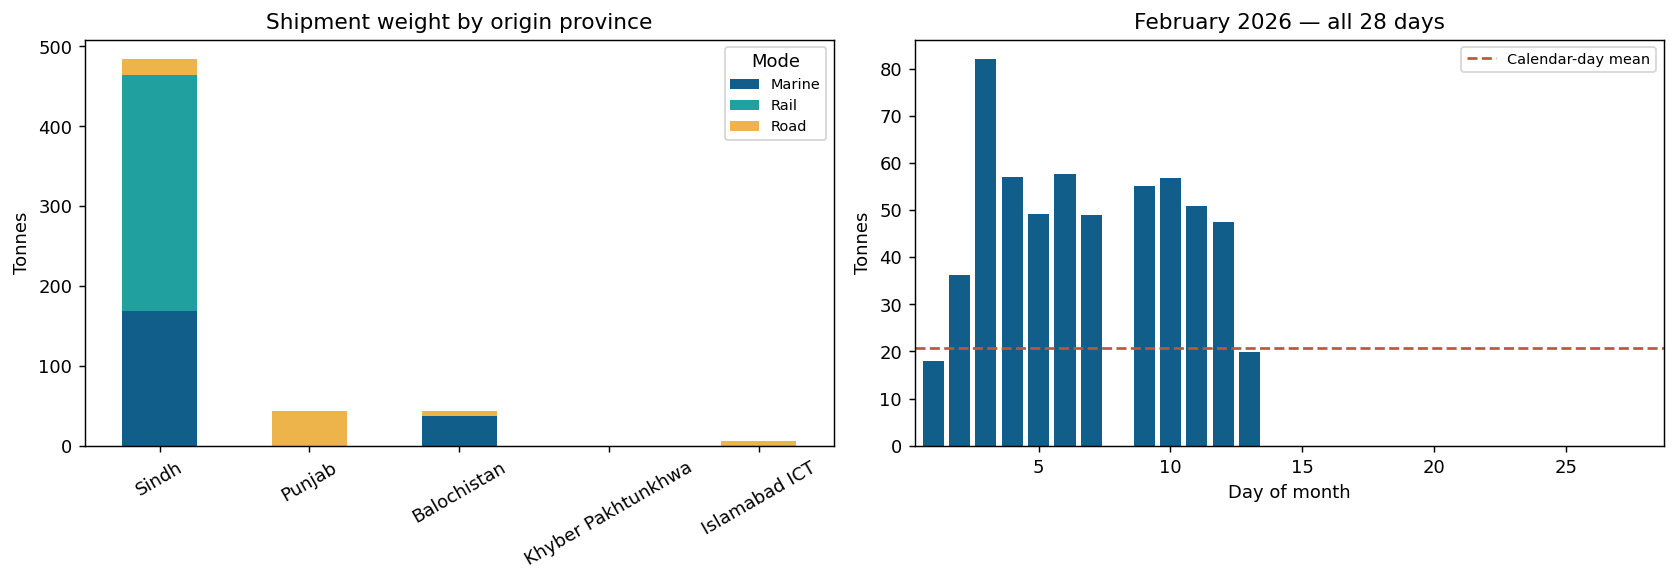

In [11]:
fig, axes = plt.subplots(1,2,figsize=(13,4.6))
origin_matrix.loc[provinces,modes].div(1000).plot.bar(stacked=True, ax=axes[0],
    color=['#125e8a','#21a0a0','#edb44c'])
axes[0].set(title='Shipment weight by origin province',ylabel='Tonnes',xlabel='')
axes[0].tick_params(axis='x',labelrotation=30)
axes[0].legend(title='Mode',fontsize=8)
axes[1].bar(daily_activity.FullDate.dt.day,daily_activity.WeightKG/1000,color='#125e8a')
axes[1].axhline(daily_activity.WeightKG.mean()/1000,color='#bd5837',linestyle='--',label='Calendar-day mean')
axes[1].set(title='February 2026 — all 28 days',xlabel='Day of month',ylabel='Tonnes',xlim=(0.3,28.7))
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Additional integrity checks and reproducible exports
These checks verify dimension keys, referential integrity, full calendar coverage and the unknown-row path. A synthetic unmatched record is tested separately and is never added to the assignment fact table. Surrogate keys are deterministic for this fixed dataset; a production load must persist key assignments rather than renumbering cities/routes on each refresh.

In [12]:
model_tables = {'FactShipment':fact,'DimCity':dim_city,'DimRoute':dim_route,
                'DimDate':dim_date,'DimMode':dim_mode,'DimStatus':dim_status}
for relation in relationships.itertuples(index=False):
    dim = model_tables[relation.Dimension]
    pk = dim[relation.DimensionColumn]
    assert pk.is_unique and pk.notna().all()
    assert -1 in pk.values
    assert fact[relation.FactColumn].isin(pk).all()
assert fact.columns.tolist()==fact_columns and fact.shape==(34,10)
assert fact[key_columns].notna().all().all()
assert all(pd.api.types.is_integer_dtype(fact[c]) for c in key_columns)
assert calendar.FullDate.equals(pd.Series(pd.date_range('2026-02-01','2026-02-28'),name='FullDate'))
assert source.equals(source_original)
assert dim_city.loc[dim_city.CityName.eq('Karachi'),'CityKey'].item()==1
assert daily_activity.InFactTable.sum()==12
assert (~daily_activity.InFactTable).sum()==16
probe = source.iloc[[0]].copy()
probe['Origin'] = 'Unmapped location'
probe['Status'] = 'Unmapped status'
probe['SourceSystem'] = 'Unmapped mode'
probe['ShipDate'] = pd.NaT
probe_fact, probe_audit = build_fact(probe)
assert len(probe_fact)==1 and len(probe_audit)==1
assert probe_fact[['OriginCityKey','RouteKey','ModeKey','StatusKey','DateKey']].eq(-1).all().all()
assert probe_fact.WeightKG.sum()==probe.WeightKG.sum()
print('Integrity checks PASS; unmatched test record retained with Unknown keys.')

output_dir = Path('pakfreight_outputs')
output_dir.mkdir(exist_ok=True)
for name,table in model_tables.items():
    table.to_csv(output_dir/f'{name}.csv',index=False)
city_map.to_csv(output_dir/'CityAliasMap.csv',index=False)
calendar.to_csv(output_dir/'Calendar_28_Days.csv',index=False)
validation.to_csv(output_dir/'Reconciliation.csv',index=False)
relationships.to_csv(output_dir/'Relationships.csv',index=False)
origin_matrix.to_csv(output_dir/'OriginProvince_Mode_KG.csv')
destination_matrix.to_csv(output_dir/'DestinationProvince_Mode_KG.csv')
print('Exported six model tables plus mapping, calendar, checks, relationships and both matrices to:',output_dir.resolve())

Integrity checks PASS; unmatched test record retained with Unknown keys.
Exported six model tables plus mapping, calendar, checks, relationships and both matrices to: /workspace/scratch/fe10a190d140/pakfreight_outputs


## Conclusion
The transformation preserves **34 shipment legs, 578,650 kg and PKR 4,808,000**. It produces **14 real cities**, **20 real routes**, a complete **28-day calendar**, and reserved Unknown members. All **13 reconciliation checks pass**. National cost is **PKR 8.31/kg**; KP has **0 kg outbound** and **61,900 kg inbound**, demonstrating why the city role must be explicit.

**Sources:** supplied `PakFreight_W3_StarBuilder_STUDENT.xlsx`, `PowerBI_Lab_Guide.md`, `Shipments_Unified (1).csv`, and the two identical `raw_locations` CSV templates. Geographic grouping follows the assignment; region/corridor/distance-band conventions are explicitly documented assumptions.